# Exploratory Data Analysis (EDA)

Project developed for the **Artificial Intelligence** course at **Instituto Politécnico do Cávado e do Ave (IPCA)**.

Group members:

- **João Paulo Carvalho** — 27991  
- **Pedro Taveira** — 27986  
- **Alexandre Vilaça** — 26590  
- **Licínio Cunha** — 25454  

Dataset: **AI_Impact_on_Jobs_2030**

## Notebook Structure

1. Load and quick overview
2. Variable dictionary/description
3. Data quality checks (types, missing values, duplicates)
4. Descriptive statistics
5. Univariate analysis (distributions)
6. Bivariate analysis (key relationships)
7. Group comparisons (Risk_Category and Education_Level)
8. Correlations and `Skill_*` analysis
9. Jobs with highest/lowest risk (mean)
10. Outlier demo (synthetic)
11. Key takeaways

In [1]:
# Import required libraries

# Data processing
import pandas as pd
import numpy as np

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Settings
pd.set_option('display.max_columns', 200)
pd.set_option('display.width', 120)
sns.set_theme(style='whitegrid')

## Load data

This section loads the dataset from the CSV file and confirms that it was read correctly (number of rows/columns). It’s a quick sanity check before any analysis.

In [2]:
# Load dataset
df = pd.read_csv('./AI_Impact_on_Jobs_2030.csv')

# Quick view
df.shape

(3000, 18)

## Variable description

- `Job_Title`: job role/title
- `Average_Salary`: average salary (numeric)
- `Years_Experience`: years of experience
- `Education_Level`: education level (categorical)
- `AI_Exposure_Index`: AI exposure index (0–1)
- `Tech_Growth_Factor`: technological growth factor (continuous)
- `Automation_Probability_2030`: automation probability by 2030 (0–1)
- `Risk_Category`: risk category (Low/Medium/High)
- `Skill_1` … `Skill_10`: numeric indicators (0–1) representing skills/competencies

In [3]:
df.head()

,Job_Title,Average_Salary,Years_Experience,Education_Level,AI_Exposure_Index,Tech_Growth_Factor,Automation_Probability_2030,Risk_Category,Skill_1,Skill_2,Skill_3,Skill_4,Skill_5,Skill_6,Skill_7,Skill_8,Skill_9,Skill_10
0,Security Guard,45795,28,Master's,0.18,1.28,0.85,High,0.45,0.10,0.46,0.33,0.14,0.65,0.06,0.72,0.94,0.00
1,Research Scientist,133355,20,PhD,0.62,1.11,0.05,Low,0.02,0.52,0.40,0.05,0.97,0.23,0.09,0.62,0.38,0.98
2,Construction Worker,146216,2,High School,0.86,1.18,0.81,High,0.01,0.94,0.56,0.39,0.02,0.23,0.24,0.68,0.61,0.83
3,Software Engineer,136530,13,PhD,0.39,0.68,0.60,Medium,0.43,0.21,0.57,0.03,0.84,0.45,0.40,0.93,0.73,0.33
4,Financial Analyst,70397,22,High School,0.52,1.46,0.64,Medium,0.75,0.54,0.59,0.97,0.61,0.28,0.30,0.17,0.02,0.42


In [4]:
# Columns, dtypes, and a random sample
display(pd.DataFrame({'column': df.columns, 'dtype': df.dtypes.astype(str)}))
df.sample(5, random_state=42)

,column,dtype
Job_Title,Job_Title,str
Average_Salary,Average_Salary,int64
Years_Experience,Years_Experience,int64
Education_Level,Education_Level,str
AI_Exposure_Index,AI_Exposure_Index,float64
Tech_Growth_Factor,Tech_Growth_Factor,float64
Automation_Probability_2030,Automation_Probability_2030,float64
Risk_Category,Risk_Category,str
Skill_1,Skill_1,float64
Skill_2,Skill_2,float64


,Job_Title,Average_Salary,Years_Experience,Education_Level,AI_Exposure_Index,Tech_Growth_Factor,Automation_Probability_2030,Risk_Category,Skill_1,Skill_2,Skill_3,Skill_4,Skill_5,Skill_6,Skill_7,Skill_8,Skill_9,Skill_10
1801,UX Researcher,146298,6,Bachelor's,0.64,1.04,0.54,Medium,0.68,0.17,0.30,0.74,0.16,0.34,0.67,0.94,0.08,0.52
1190,Construction Worker,134042,12,High School,0.79,1.41,0.75,High,0.52,0.84,0.11,0.79,0.18,0.81,0.61,0.19,0.47,0.68
1817,Financial Analyst,64118,5,PhD,0.28,0.94,0.45,Medium,0.74,0.60,0.65,0.21,0.33,0.02,0.11,0.27,0.07,0.60
251,Mechanic,105831,22,Master's,0.80,0.83,0.42,Medium,0.23,0.13,0.26,0.36,0.67,0.06,0.21,0.81,0.15,0.34
2505,Data Scientist,73489,2,Master's,0.32,0.93,0.34,Medium,1.00,0.76,0.62,0.59,0.50,0.26,0.23,0.55,0.07,0.07


## Data quality (missing values and duplicates)

We check for missing values and duplicate rows. If the data is incomplete or duplicated, it can bias averages, correlations, and plots.

In [5]:
# Missing values per column
missing = df.isna().sum().sort_values(ascending=False)
display(missing[missing > 0])

# Missing percentage
missing_pct = (df.isna().mean() * 100).sort_values(ascending=False)
display(missing_pct[missing_pct > 0].round(2))

# Duplicated rows
df.duplicated().sum()

Series([], dtype: int64)

Series([], dtype: float64)

np.int64(0)

## Descriptive statistics

This section summarizes the dataset:
- Numeric columns: mean, std, percentiles, etc.
- Categorical columns: frequency counts (most common categories).
This gives a baseline understanding of typical values and variability.

In [6]:
num_cols = df.select_dtypes(include=np.number).columns.tolist()
cat_cols = df.select_dtypes(exclude=np.number).columns.tolist()

print('Numeric:', num_cols)
print('Categorical:', cat_cols)

# Descriptive stats for numeric columns
df[num_cols].describe().T

Numeric: ['Average_Salary', 'Years_Experience', 'AI_Exposure_Index', 'Tech_Growth_Factor', 'Automation_Probability_2030', 'Skill_1', 'Skill_2', 'Skill_3', 'Skill_4', 'Skill_5', 'Skill_6', 'Skill_7', 'Skill_8', 'Skill_9', 'Skill_10']
Categorical: ['Job_Title', 'Education_Level', 'Risk_Category']


,count,mean,std,min,25%,50%,75%,max
Average_Salary,3000.0,89372.279000,34608.088767,30030.00,58640.00,89318.000,119086.50,149798.00
Years_Experience,3000.0,14.677667,8.739788,0.00,7.00,15.000,22.00,29.00
AI_Exposure_Index,3000.0,0.501283,0.284004,0.00,0.26,0.500,0.74,1.00
Tech_Growth_Factor,3000.0,0.995343,0.287669,0.50,0.74,1.000,1.24,1.50
Automation_Probability_2030,3000.0,0.501503,0.247881,0.05,0.31,0.500,0.70,0.95
Skill_1,3000.0,0.496973,0.287888,0.00,0.24,0.505,0.74,1.00
Skill_2,3000.0,0.497233,0.288085,0.00,0.25,0.500,0.74,1.00
Skill_3,3000.0,0.499313,0.288354,0.00,0.25,0.500,0.75,1.00
Skill_4,3000.0,0.503667,0.287063,0.00,0.26,0.510,0.75,1.00
Skill_5,3000.0,0.490270,0.285818,0.00,0.24,0.490,0.73,1.00


In [7]:
# Frequency tables for categorical variables
for col in cat_cols:
    print(f'\n{col}:')
    display(df[col].value_counts(dropna=False).head(10))


Job_Title:


Job_Title
Software Engineer      175
UX Researcher          167
Data Scientist         167
Teacher                166
Graphic Designer       160
HR Specialist          157
Construction Worker    156
Retail Worker          155
Security Guard         154
Truck Driver           153
Name: count, dtype: int64


Education_Level:


Education_Level
High School    784
Bachelor's     765
Master's       735
PhD            716
Name: count, dtype: int64


Risk_Category:


Risk_Category
Medium    1521
High       740
Low        739
Name: count, dtype: int64

## Univariate analysis (distributions)

Univariate analysis looks at each variable on its own (one at a time). The goal is to understand distributions, skewness, and potential outliers.

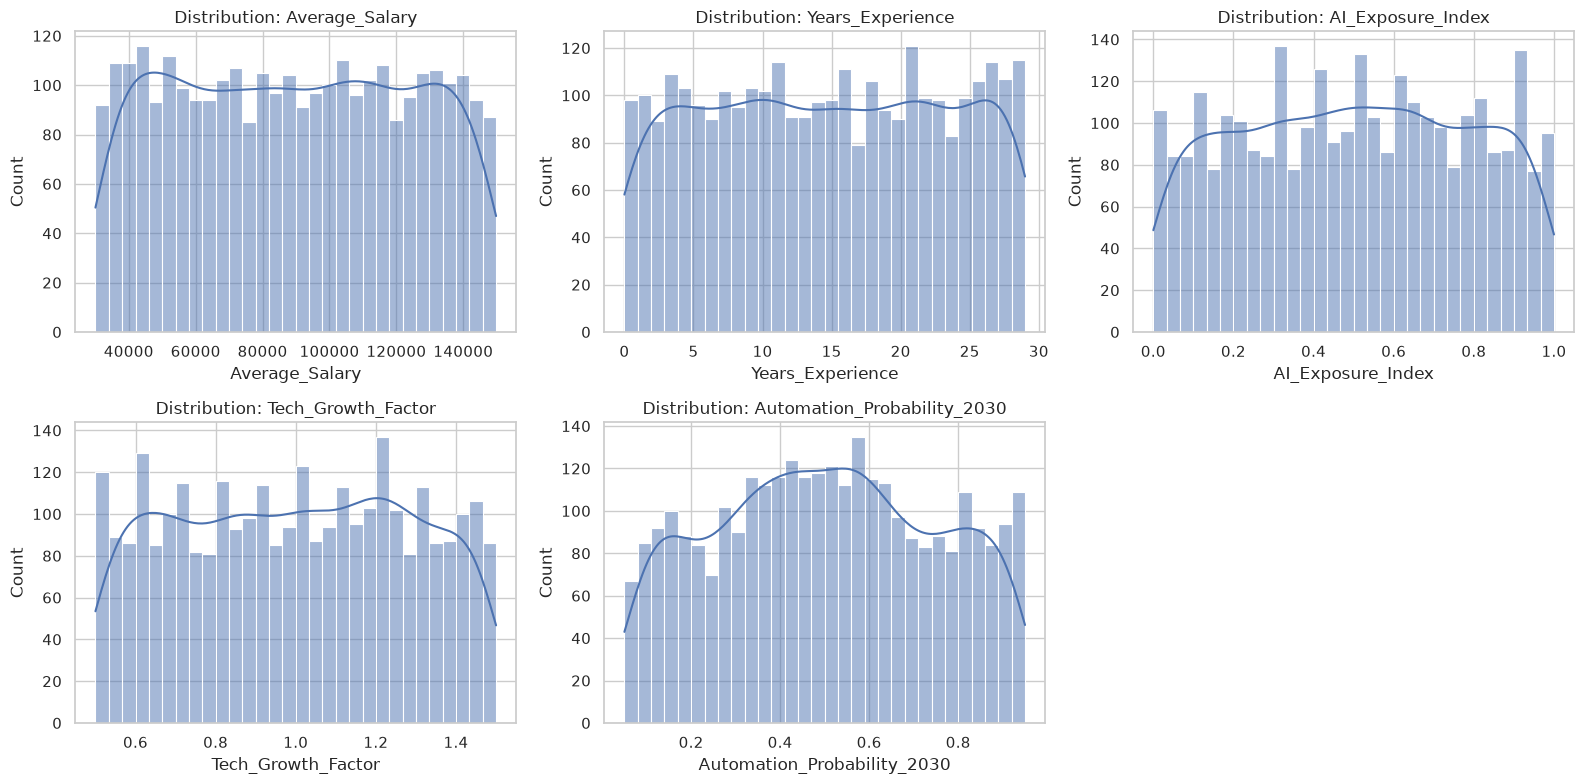

In [8]:
# Distributions of key numeric variables
main_numeric = ['Average_Salary', 'Years_Experience', 'AI_Exposure_Index', 'Tech_Growth_Factor', 'Automation_Probability_2030']
main_numeric = [c for c in main_numeric if c in df.columns]

fig, axes = plt.subplots(2, 3, figsize=(16, 8))
axes = axes.flatten()
for i, col in enumerate(main_numeric):
    sns.histplot(df[col], kde=True, ax=axes[i], bins=30)
    axes[i].set_title(f'Distribution: {col}')
for j in range(i + 1, len(axes)):
    axes[j].axis('off')
plt.tight_layout()
plt.show()

## Bivariate analysis (key relationships)

Bivariate analysis studies relationships between two variables. Here we focus on relationships that are relevant to the project questions (risk, AI exposure, automation probability, salary).

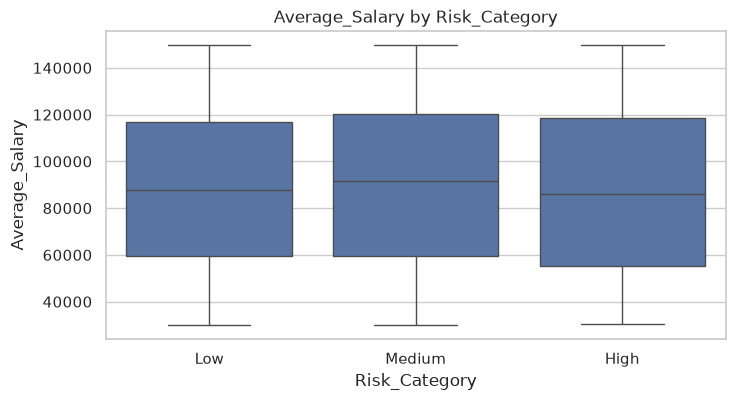

In [9]:
# Salary vs risk category
if 'Average_Salary' in df.columns and 'Risk_Category' in df.columns:
    plt.figure(figsize=(8, 4))
    order_risk = ['Low', 'Medium', 'High']
    sns.boxplot(data=df, x='Risk_Category', y='Average_Salary', order=[x for x in order_risk if x in df['Risk_Category'].unique()])
    plt.title('Average_Salary by Risk_Category')
    plt.show()

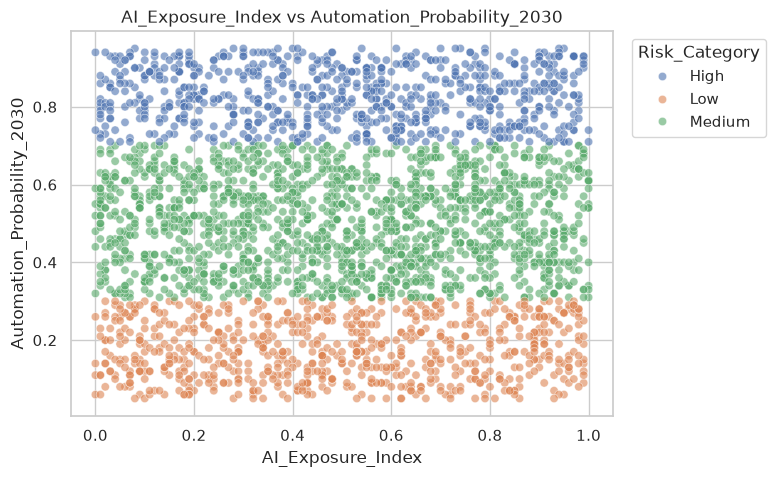

In [10]:
# AI exposure vs automation probability
needed = {'AI_Exposure_Index', 'Automation_Probability_2030'}
if needed.issubset(df.columns):
    plt.figure(figsize=(7, 5))
    if 'Risk_Category' in df.columns:
        sns.scatterplot(data=df, x='AI_Exposure_Index', y='Automation_Probability_2030', hue='Risk_Category', alpha=0.6)
        plt.legend(title='Risk_Category', bbox_to_anchor=(1.02, 1), loc='upper left')
    else:
        sns.scatterplot(data=df, x='AI_Exposure_Index', y='Automation_Probability_2030', alpha=0.6)
    plt.title('AI_Exposure_Index vs Automation_Probability_2030')
    plt.show()

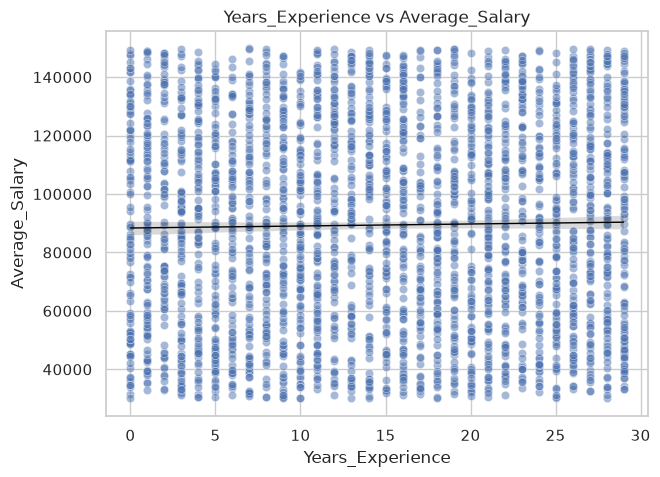

In [11]:
# Salary vs experience
needed = {'Years_Experience', 'Average_Salary'}
if needed.issubset(df.columns):
    plt.figure(figsize=(7, 5))
    sns.scatterplot(data=df, x='Years_Experience', y='Average_Salary', alpha=0.5)
    sns.regplot(data=df, x='Years_Experience', y='Average_Salary', scatter=False, color='black', line_kws={'linewidth': 1})
    plt.title('Years_Experience vs Average_Salary')
    plt.show()

## Group comparisons (Risk_Category and Education_Level)

This section summarizes key numeric variables by category and adds distribution plots to compare groups.

Its focused on:
- `Average_Salary`
- `AI_Exposure_Index`
- `Automation_Probability_2030`

Grouped statistics by Risk_Category:


Average_Salary                                AI_Exposure_Index                       \
                       count       mean   median        std             count   mean median    std   
Risk_Category                                                                                        
High                     740  87359.442  86120.0  34992.743               740  0.510   0.53  0.285   
Low                      739  89166.777  87889.0  33739.475               739  0.496   0.48  0.289   
Medium                  1521  90451.415  91775.0  34813.012              1521  0.500   0.50  0.281   

              Automation_Probability_2030                       
                                    count   mean median    std  
Risk_Category                                                   
High                                  740  0.830   0.83  0.070  
Low                                   739  0.177   0.17  0.073  
Medium                               1521  0.500   0.50  0.112


Grouped statistics by Education_Level:


Average_Salary                                AI_Exposure_Index                       \
                         count       mean   median        std             count   mean median    std   
Education_Level                                                                                        
Bachelor's                 765  88815.495  89309.0  34343.929               765  0.497   0.49  0.285   
High School                784  88389.293  87709.5  34573.992               784  0.498   0.50  0.281   
Master's                   735  91318.565  92086.0  34199.181               735  0.503   0.50  0.281   
PhD                        716  89045.575  87818.5  35331.041               716  0.508   0.52  0.289   

                Automation_Probability_2030                       
                                      count   mean median    std  
Education_Level                                                   
Bachelor's                              765  0.500   0.49  0.248  
High School                             784  0.509   0.52  0.240  
Master's                                735  0.496   0.50  0.252  
PhD                                     716  0.500   0.49  0.252

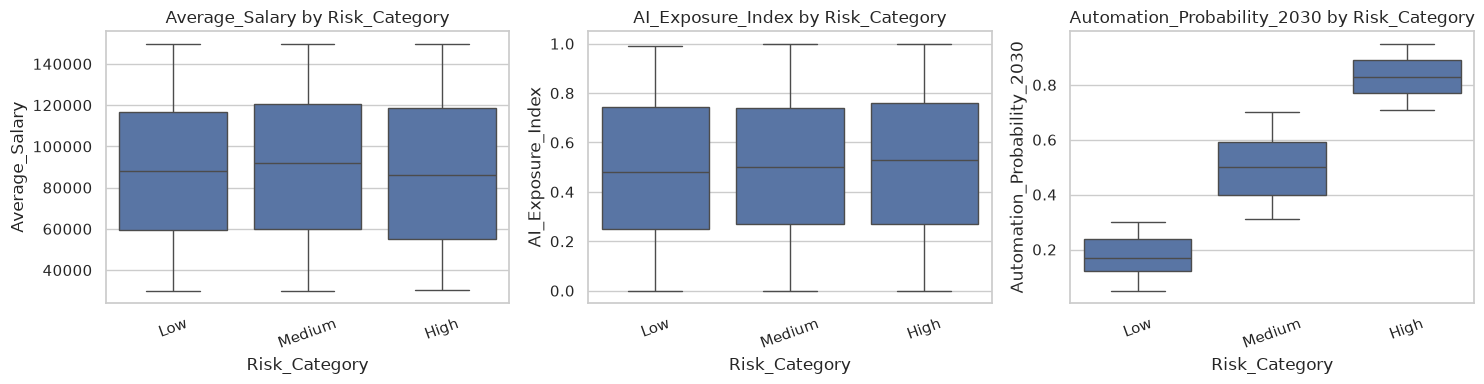

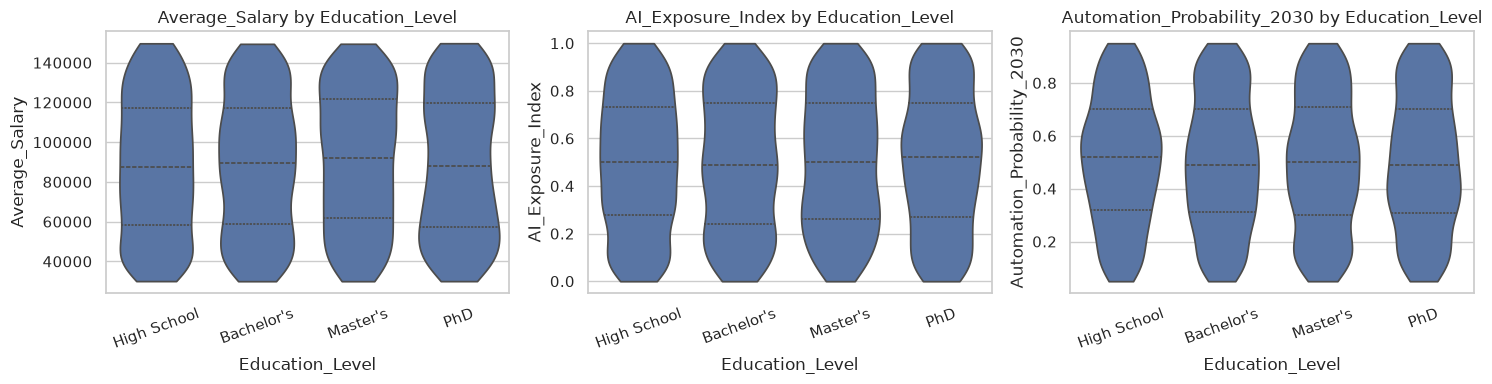

In [12]:
# Grouped descriptive statistics + box/violin plots
group_vars = [c for c in ['Average_Salary', 'AI_Exposure_Index', 'Automation_Probability_2030'] if c in df.columns]
if not group_vars:
    print('No expected numeric columns found for grouped analysis.')
else:
    # --- Grouped tables ---
    if 'Risk_Category' in df.columns:
        print('Grouped statistics by Risk_Category:')
        display(df.groupby('Risk_Category')[group_vars].agg(['count', 'mean', 'median', 'std']).round(3))
    else:
        print("Column 'Risk_Category' not found.")
    
    if 'Education_Level' in df.columns:
        print('\nGrouped statistics by Education_Level:')
        display(df.groupby('Education_Level')[group_vars].agg(['count', 'mean', 'median', 'std']).round(3))
    else:
        print("Column 'Education_Level' not found.")
    
    # --- Plots ---
    # Risk_Category: boxplots
    if 'Risk_Category' in df.columns:
        order_risk = ['Low', 'Medium', 'High']
        risk_order = [x for x in order_risk if x in df['Risk_Category'].unique()]
        fig, axes = plt.subplots(1, len(group_vars), figsize=(5 * len(group_vars), 4), sharex=False)
        if len(group_vars) == 1:
            axes = [axes]
        for ax, col in zip(axes, group_vars):
            sns.boxplot(data=df, x='Risk_Category', y=col, order=risk_order, ax=ax)
            ax.set_title(f'{col} by Risk_Category')
            ax.tick_params(axis='x', rotation=20)
        plt.tight_layout()
        plt.show()
    
    # Education_Level: violin plots
    if 'Education_Level' in df.columns:
        order_edu = ["High School", "Bachelor's", "Master's", "PhD"]
        edu_order = [x for x in order_edu if x in df['Education_Level'].unique()]
        if not edu_order:
            edu_order = sorted(df['Education_Level'].dropna().unique().tolist())
        fig, axes = plt.subplots(1, len(group_vars), figsize=(5 * len(group_vars), 4), sharex=False)
        if len(group_vars) == 1:
            axes = [axes]
        for ax, col in zip(axes, group_vars):
            sns.violinplot(data=df, x='Education_Level', y=col, order=edu_order, inner='quartile', cut=0, ax=ax)
            ax.set_title(f'{col} by Education_Level')
            ax.tick_params(axis='x', rotation=20)
        plt.tight_layout()
        plt.show()

## Correlations and skill analysis (`Skill_*`)

This section explores linear relationships between numeric variables using a correlation matrix. It also summarizes the `Skill_*` columns by creating `Skill_Mean` and `Skill_Std`, which provide a compact view of the skill indicators.

Most correlations are close to 0, the heatmap may look “uniform” even though values differ slightly.

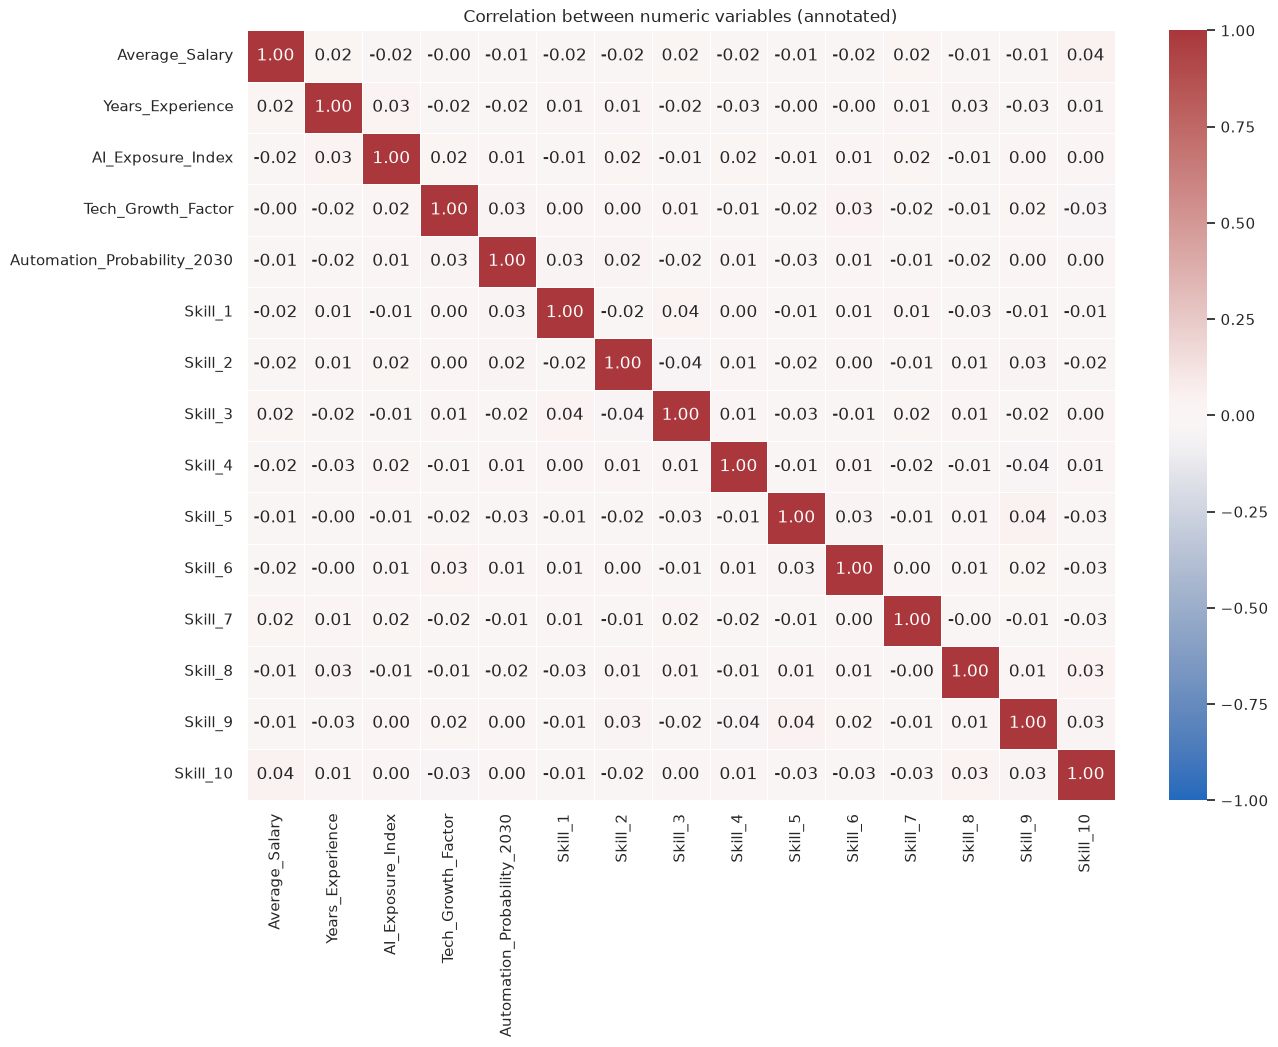

In [13]:
# Correlation matrix (numeric features)
plt.figure(figsize=(14, 10))
corr = df.select_dtypes(include=np.number).corr()
sns.heatmap(corr, cmap='vlag', center=0, vmin=-1, vmax=1, linewidths=0.5, annot=True, fmt='.2f')
plt.title('Correlation between numeric variables (annotated)')
plt.show()

,count,mean,std,min,25%,50%,75%,max
Skill_Mean,3000.0,0.498433,0.090470,0.222000,0.4380,0.50000,0.556000,0.796000
Skill_Std,3000.0,0.283615,0.046896,0.097005,0.2535,0.28463,0.316453,0.434466


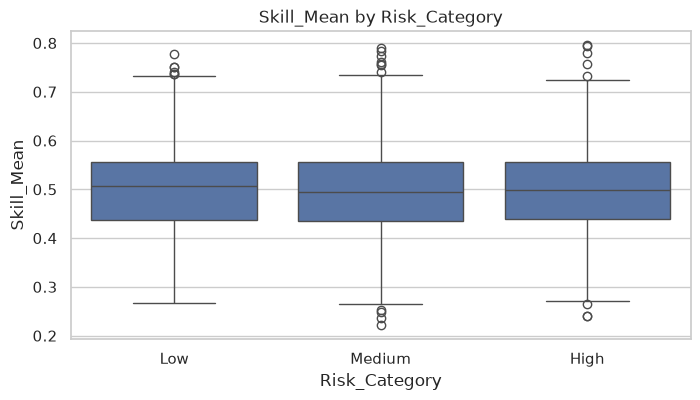

In [14]:
# Skill_* analysis
skill_cols = [c for c in df.columns if c.startswith('Skill_')]
if skill_cols:
    df['Skill_Mean'] = df[skill_cols].mean(axis=1)
    df['Skill_Std'] = df[skill_cols].std(axis=1)
    display(df[['Skill_Mean', 'Skill_Std']].describe().T)

    if 'Risk_Category' in df.columns:
        plt.figure(figsize=(8, 4))
        order_risk = ['Low', 'Medium', 'High']
        sns.boxplot(data=df, x='Risk_Category', y='Skill_Mean', order=[x for x in order_risk if x in df['Risk_Category'].unique()])
        plt.title('Skill_Mean by Risk_Category')
        plt.show()

## Jobs with highest/lowest risk (mean)

Here we aggregate by `Job_Title` and compute the mean `Automation_Probability_2030` per job. This highlights which roles are most/least exposed to automation risk in the dataset.

,mean_automation_prob
Job_Title,
Retail Worker,0.834710
Security Guard,0.833052
Construction Worker,0.825962
Customer Support,0.825263
Truck Driver,0.818627
Graphic Designer,0.529000
Software Engineer,0.508686
Data Scientist,0.496287
Chef,0.495674


,mean_automation_prob
Job_Title,
UX Researcher,0.492395
HR Specialist,0.490764
Lawyer,0.486439
Mechanic,0.485294
Financial Analyst,0.485099
Doctor,0.176742
Teacher,0.175783
Nurse,0.175634
Research Scientist,0.174161


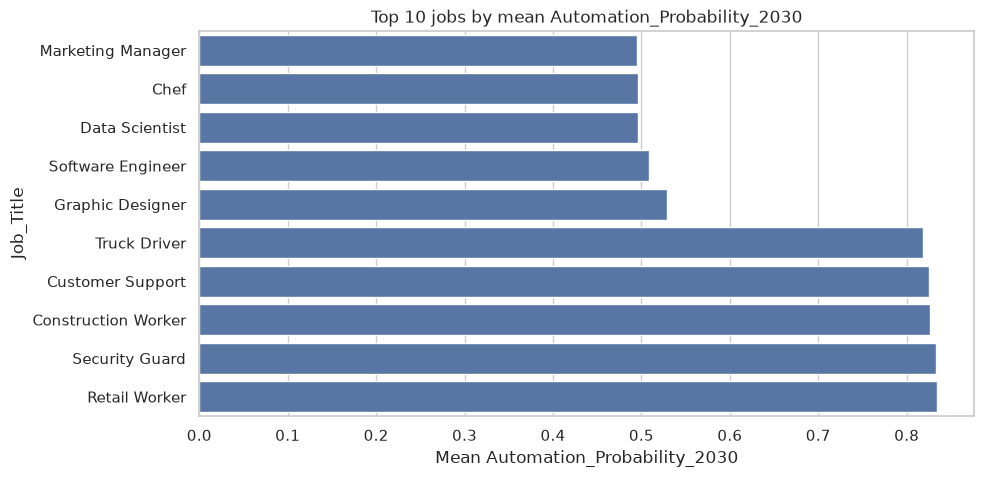

In [15]:
if {'Job_Title', 'Automation_Probability_2030'}.issubset(df.columns):
    job_risk = (df.groupby('Job_Title', as_index=True)['Automation_Probability_2030']
                  .mean()
                  .sort_values(ascending=False))

    display(job_risk.head(10).to_frame('mean_automation_prob'))
    display(job_risk.tail(10).to_frame('mean_automation_prob'))

    # Plot top 10
    plt.figure(figsize=(10, 5))
    top10 = job_risk.head(10).sort_values()
    sns.barplot(x=top10.values, y=top10.index)
    plt.title('Top 10 jobs by mean Automation_Probability_2030')
    plt.xlabel('Mean Automation_Probability_2030')
    plt.ylabel('Job_Title')
    plt.show()

## Outlier demo (synthetic)

This is a small demonstration that injects a synthetic outlier **without modifying the original `df`**. It helps verify that the IQR and z-score rules can flag extreme values when they exist.

Injected salary outlier at index 150: 149798 -> 1497980
IQR bounds: [-1806.50, 179533.00] | IQR outliers: 1
Z-threshold: 2.5 | Z outliers: 1


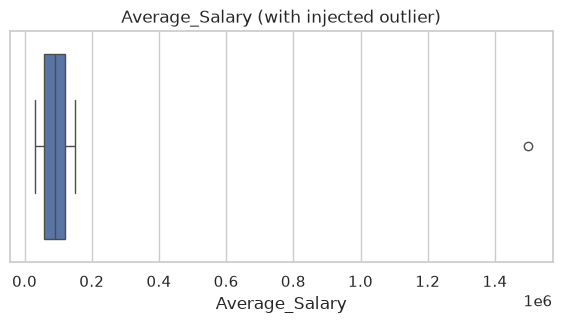

In [16]:
# Demo: inject a synthetic outlier (does NOT modify df)
df_demo = df.copy()

if 'Average_Salary' in df_demo.columns:
    # Pick a valid row and inflate salary to create a clear outlier
    idx = df_demo['Average_Salary'].dropna().idxmax()
    old_val = df_demo.loc[idx, 'Average_Salary']
    df_demo.loc[idx, 'Average_Salary'] = old_val * 10
    new_val = df_demo.loc[idx, 'Average_Salary']
    print(f'Injected salary outlier at index {idx}: {old_val} -> {new_val}')

    # Detect outliers using IQR and z-score
    s = df_demo['Average_Salary'].dropna()
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1
    iqr_multiplier = 1.0
    lower, upper = q1 - iqr_multiplier * iqr, q3 + iqr_multiplier * iqr
    iqr_mask = (df_demo['Average_Salary'] < lower) | (df_demo['Average_Salary'] > upper)
    print(f'IQR bounds: [{lower:.2f}, {upper:.2f}] | IQR outliers: {int(iqr_mask.sum())}')

    z_threshold = 2.5
    z = (df_demo['Average_Salary'] - df_demo['Average_Salary'].mean()) / df_demo['Average_Salary'].std(ddof=0)
    z_mask = z.abs() > z_threshold
    print(f'Z-threshold: {z_threshold} | Z outliers: {int(z_mask.sum())}')

    # Visual confirmation
    plt.figure(figsize=(7, 3))
    sns.boxplot(x=df_demo['Average_Salary'])
    plt.title('Average_Salary (with injected outlier)')
    plt.show()
else:
    print("Column 'Average_Salary' not found; cannot inject a salary outlier.")

## Key takeaways (summary)

In this EDA we explored:

- Distributions of salary, experience, AI exposure, and automation probability
- Distributions of education level and risk category
- Relationships between AI exposure and automation probability, and between risk and salary
- Correlations and a summary view of the `Skill_*` features
- Jobs with the highest/lowest mean automation probability by 2030
- A synthetic outlier demo to validate IQR/z-score detection